**Model.** The computational domain is a single grating cell of length $2\pi/k_g$ with Floquet-periodic lateral boundaries (wave vector $(0,0)$) and PMLs truncating the domain far from the surface. The excitation is an $s$-polarized (TE) plane wave at normal incidence, $f = 5$ THz ($\lambda_0 \approx 60\ \mu$m). All complex quantities use the $e^{-i\omega t}$ convention; the FEM solver uses the conjugate material data, i.e. its own $e^{+i\omega t}$ sign convention.

**Grating and ionized layer.** The surface is sinusoidally corrugated along $z$, $h(z) = h_0\cos(k_g z)$ with $k_0 h_0 \ll 1$ (relief depth $h_0 = 30$ nm), and the corrugation is the only source of diffraction ($\delta\varepsilon = 0$). With $g = 10^6\ \mathrm{m}^{-1}$ (period $\Lambda = 2\pi/g = 6.28\ \mu$m) and ionization depth $\gamma^{-1} = 1\ \mu$m ($\gamma = g$) the relative permittivity of the ionized layer is

$$\varepsilon(x,z) = \underbrace{11.7 + 2i}_{\varepsilon_0\ \mathrm{(lossy\ background)}} + \underbrace{(-30+50i)}_{\varepsilon_p}.$$


**Zero-order field.** $E_y^0 = 0.16354 - 0.18728j$ is taken from the separate FEM run with the corrugation switched off.

**Analytical curve.** 

Eq. (53) at the surface reads

$$E^{\mathrm{tot}}(0,0) = E_y^0\left[1 + \frac{h_0 k_0^2(\varepsilon-1)}{\eta_2 - \eta_1}\cos(k_g z)\right].$$

In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 8,
    "axes.titlesize": 8, "axes.labelsize": 8,
    "xtick.labelsize": 7, "ytick.labelsize": 7,
    "legend.fontsize": 6.5,
    "axes.linewidth": 0.7,
    "lines.linewidth": 1.0, "lines.markersize": 3.0,
    "lines.markeredgewidth": 0.5,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.top": True, "ytick.right": True,
    "xtick.major.size": 2.5, "ytick.major.size": 2.5,
    "xtick.major.pad": 2.0, "ytick.major.pad": 2.0,
    "axes.labelpad": 2.5,
})

c_const = 2.99792458e8          # m/s
omega   = 2 * np.pi * 5e12      # Hz
k0      = omega / c_const       # 1/m
g       = 1.0e6                 # 1/m  
eps0        = 11.7 + 2j + (-30 + 50j)
h0 = 30*1e-9                    # m 

In [2]:
# ===== FEM reference: complex field at (0,0) =====
data_str = np.loadtxt("../data/e_complex_g_no_gamma.txt", comments="%", dtype=str, skiprows=1)

kg_m   = data_str[:, 0].astype(float)
kg_cm  = kg_m / 100
ez_fem = np.array([complex(x.replace("i", "j")) for x in data_str[:, 1]])

Ey0     = 0.16354 - 0.18728j
Ey0_fem = np.conj(Ey0)          # FEM uses the conjugate (e^{+iωt}) convention
ez_norm = np.real((ez_fem - Ey0_fem) / Ey0_fem)

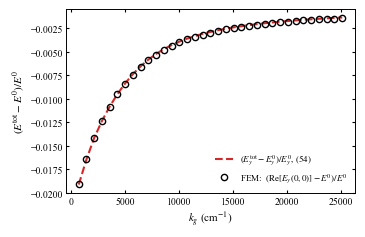

In [3]:
z1   = kg_m**2 - k0**2
eta1 = np.sqrt(z1.astype(complex))
eta1 = np.where(eta1.real > 0, -eta1, eta1)

z2   = kg_m**2 - k0**2 * eps0
eta2 = np.sqrt(z2.astype(complex))
eta2 = np.where(eta2.real > 0, eta2, -eta2)

z = 0

Ey = Ey0 * (
    1
    + (k0**2 * h0)*(eps0 - 1) / (eta2 - eta1)
    * np.cos(kg_cm * z)
)

Ey_re = np.real((Ey - Ey0) / Ey0)

fig, ax = plt.subplots(figsize=(3.543, 4.535/2))
ax.plot(kg_cm, Ey_re, "--", color="C3", lw=1.5,
        label=r"$(E^{\mathrm{tot}}_y-E^0_y)/E^0_y$, (54)")
ax.plot(kg_cm, ez_norm, "o", color="k", ms=4.5, mfc="none",
        markeredgewidth=1.0, label=r"FEM:  $(\mathrm{Re}[E_y(0,0)]-E^0)/E^0$")
ax.set_xlabel(r"$k_g$ (cm$^{-1}$)")
ax.set_ylabel(r"$(E^{\mathrm{tot}}-E^0)/E^0$")
ax.legend(frameon=False, loc="lower right")

fig.tight_layout(pad=0.4)
fig.savefig("../Figs/fig_6.png", dpi=600, bbox_inches="tight", pad_inches=0.02)
fig.savefig("../Figs/fig_6.pdf")
plt.show()
